In [88]:
import pandas as pd
import numpy as np

df = pd.read_csv("student_performance_regression_560.csv")

In [89]:
cat_cols = []
num_cols = []

for col in df.columns:
    if df[col].dtype == "object" or df[col].dtype == "str":
        cat_cols.append(col)
    else:
        num_cols.append(col)

print("cat cols\n", cat_cols)
print("num cols\n", num_cols)

cat cols
 ['Family_Income', 'Study_Environment', 'Learning_Style', 'Internet_Quality', 'Part_Time_Job', 'Course_Type', 'Parent_Education', 'Has_Tutor']
num cols
 ['Study_Hours_Daily', 'Attendance_Percent', 'Sleep_Hours', 'Assignment_Average', 'Previous_Exam_Score', 'Screen_Time_Hours', 'Travel_Time_Minutes', 'Weekly_Exercise_Hours', 'Internet_Study_Hours', 'Stress_Level_1_to_10', 'Age', 'Final_Exam_Score']


In [90]:
for col in cat_cols:
    print("before", col, df[col].isnull().sum())
    df[col] = df[col].fillna(df[col].mode()[0])
    print("after", col, df[col].isnull().sum())

for col in num_cols:
    print("before", col, df[col].isnull().sum())
    df[col] = df[col].fillna(df[col].median())
    print("after", col, df[col].isnull().sum())

before Family_Income 0
after Family_Income 0
before Study_Environment 0
after Study_Environment 0
before Learning_Style 0
after Learning_Style 0
before Internet_Quality 0
after Internet_Quality 0
before Part_Time_Job 0
after Part_Time_Job 0
before Course_Type 0
after Course_Type 0
before Parent_Education 0
after Parent_Education 0
before Has_Tutor 0
after Has_Tutor 0
before Study_Hours_Daily 0
after Study_Hours_Daily 0
before Attendance_Percent 0
after Attendance_Percent 0
before Sleep_Hours 0
after Sleep_Hours 0
before Assignment_Average 0
after Assignment_Average 0
before Previous_Exam_Score 0
after Previous_Exam_Score 0
before Screen_Time_Hours 0
after Screen_Time_Hours 0
before Travel_Time_Minutes 0
after Travel_Time_Minutes 0
before Weekly_Exercise_Hours 0
after Weekly_Exercise_Hours 0
before Internet_Study_Hours 0
after Internet_Study_Hours 0
before Stress_Level_1_to_10 0
after Stress_Level_1_to_10 0
before Age 0
after Age 0
before Final_Exam_Score 0
after Final_Exam_Score 0


In [91]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lb = Q1 - 1.5 * IQR
    ub = Q3 + 1.5 * IQR

    df = df[df[col].between(lb, ub)]

In [92]:
trans = np.log1p(df["Previous_Exam_Score"])
orig = np.expm1(trans)

y=df["Final_Exam_Score"]
X=df.drop(columns=["Final_Exam_Score"])

In [93]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import MaxAbsScaler, RobustScaler

X_numcols = StandardScaler().fit_transform(df[num_cols])


from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

X_catcols = OneHotEncoder(handle_unknown="ignore").fit_transform(df[cat_cols]).toarray()

In [94]:
X=np.concatenate((X_numcols,X_catcols),axis=1)

In [95]:
from sklearn.preprocessing import PolynomialFeatures

X_poly = PolynomialFeatures(
    degree=2, include_bias=False
).fit_transform(X)

In [96]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.8, random_state=42, stratify=None)

In [97]:
from sklearn.ensemble import BaggingClassifier, BaggingRegressor,RandomForestClassifier, RandomForestRegressor

model = RandomForestRegressor(n_estimators=20, criterion="squared_error",max_depth=2, min_samples_split=2,max_features="sqrt", random_state=42)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",20
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of

In [98]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    model, X_train, y_train, cv=kf, scoring="r2"
)

print("5-fold R2 scores:", scores)
print("Mean R2:", scores.mean())

5-fold R2 scores: [0.4748783  0.40464814 0.57946671 0.58994689 0.43575587]
Mean R2: 0.49693918237274615


In [99]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso

params = {
"n_estimators": [5,10,15,20,25],"max_samples":[0.8,1.0],"max_features":[0.6,0.8,1.0]
}

grid = RandomizedSearchCV(RandomForestRegressor(), params, cv=kf, scoring="r2", n_jobs=-1)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV R2:", grid.best_score_)

Best parameters: {'n_estimators': 15, 'max_samples': 1.0, 'max_features': 1.0}
Best CV R2: 0.9881822967584991


In [100]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("Test R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))


Test R2: 0.9840160662217874
MAE: 0.6173798449612428
MSE: 1.4496517829457414
RMSE: 1.2040148599355995


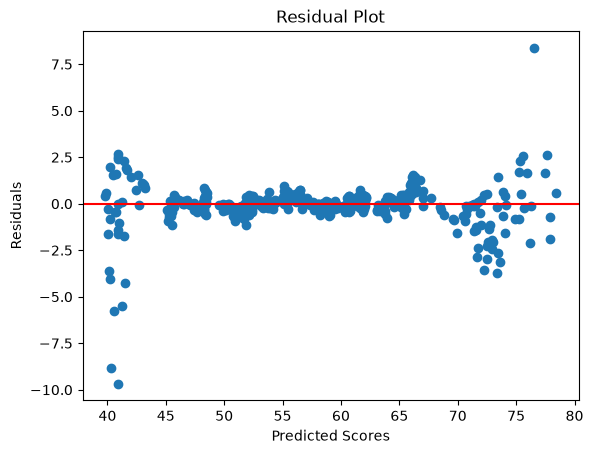

In [101]:
residuals = y_test - y_pred
import matplotlib.pyplot as plt
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color="red")
plt.xlabel("Predicted Scores")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [102]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.8, random_state=42, stratify=None)

In [103]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Original features:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])

Original features: 37
Features after PCA: 23


In [104]:
from sklearn.ensemble import BaggingClassifier, BaggingRegressor,RandomForestClassifier, RandomForestRegressor

model = RandomForestRegressor(n_estimators=20, criterion="squared_error",max_depth=2, min_samples_split=2,max_features="sqrt", random_state=42)
model.fit(X_train_pca, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",20
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of

In [105]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    model, X_train_pca, y_train, cv=kf, scoring="r2"
)

print("5-fold R2 scores:", scores)
print("Mean R2:", scores.mean())

5-fold R2 scores: [0.23822494 0.235704   0.43235008 0.35151903 0.2556219 ]
Mean R2: 0.30268399052010764


In [109]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso

params = {
"n_estimators": [5,10,15,20,25],"max_samples":[0.8,1.0],"max_features":[0.6,0.8,1.0,None]
}

#use a different variable naming
grid_pca = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    params,
    cv=kf,
    scoring="r2",
    n_jobs=-1,
    random_state=42
)

grid_pca.fit(X_train_pca, y_train)

best_model_pca = grid_pca.best_estimator_
y_pred_pca = best_model_pca.predict(X_test_pca)
print(grid_pca.best_params_)
print(grid_pca.best_score_)
print(best_model_pca)

{'n_estimators': 25, 'max_samples': 1.0, 'max_features': 0.8}
0.7985288234406107
RandomForestRegressor(max_features=0.8, max_samples=1.0, n_estimators=25,
                      random_state=42)


Best Parameters: {'n_estimators': 25, 'max_samples': 1.0, 'max_features': 0.8}
Best CV R2: 0.7985288234406107
Test R2: 0.8171067429361658
MAE: 3.2392372093023254
MSE: 16.587377041860467
RMSE: 4.072760371278976
PCA Explained Variance Ratio: [0.124925   0.09457095 0.0728429  0.0716749  0.0684956  0.06095568
 0.05832964 0.05394561 0.04870765 0.04591803 0.03925628 0.02688636
 0.02613962 0.0247812  0.02169033 0.01867662 0.01787146 0.01681052
 0.01567142 0.01472515 0.01353964 0.01239568 0.01002513]
Total Explained Variance: 0.9588353709301695


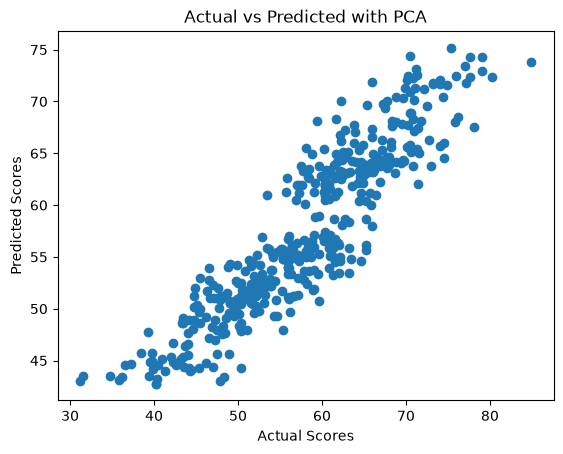

In [118]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

best_model_pca = grid_pca.best_estimator_
y_pred_pca = best_model_pca.predict(X_test_pca)

print("Best Parameters:", grid_pca.best_params_)
print("Best CV R2:", grid_pca.best_score_)
print("Test R2:", r2_score(y_test, y_pred_pca))
print("MAE:", mean_absolute_error(y_test, y_pred_pca))
print("MSE:", mean_squared_error(y_test, y_pred_pca))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_pca)))
print("PCA Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", pca.explained_variance_ratio_.sum())



import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_pca)
plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted with PCA")
plt.show()

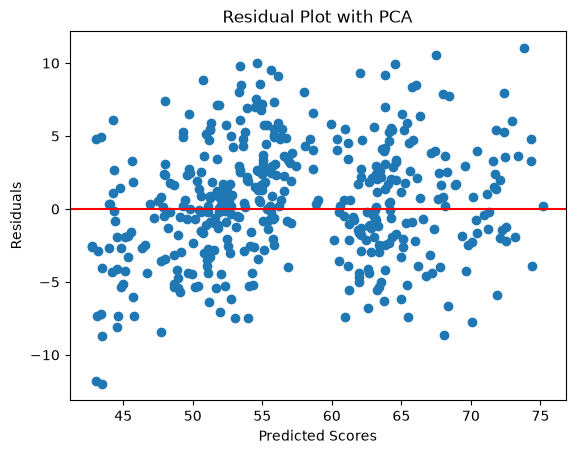

In [114]:
residuals = y_test - y_pred_pca

plt.scatter(y_pred_pca, residuals)
plt.axhline(y=0, color="red")
plt.xlabel("Predicted Scores")
plt.ylabel("Residuals")
plt.title("Residual Plot with PCA")
plt.show()

In [117]:
#FOR 2 MODELS

from scipy.stats import ttest_rel

scores_no_pca = [0.4748783  ,0.40464814, 0.57946671, 0.58994689, 0.43575587]
scores_pca = [0.23822494, 0.235704 ,  0.43235008 ,0.35151903, 0.2556219 ]

stat, p_value = ttest_rel(scores_no_pca, scores_pca)

print("P-value:", p_value)
print(stat)
if p_value < 0.05:
    print("Significant difference between models")
else:
    print("No significant difference detected")

P-value: 0.0004606024300779945
10.526509231889191
Significant difference between models


In [56]:
# #three or more tests

# from scipy.stats import friedmanchisquare, f_oneway

# model_scores = [
#     scores_model1,
#     scores_model2,
#     scores_model3
# ]
# friedman_stat, friedman_p = friedmanchisquare(*model_scores)
# anova_stat, anova_p = f_oneway(*model_scores)

# print("Friedman p-value:", friedman_p)
# print("ANOVA p-value:", anova_p)

# if friedman_p < 0.05:
#     print("Friedman: Significant difference")
# else:
#     print("Friedman: No significant difference detected")

# if anova_p < 0.05:
#     print("ANOVA: At least one model differs significantly")
# else:
#     print("ANOVA: No significant difference detected")

ValueError: At least 3 samples must be given for Friedman test, got 2.

In [ ]:
#to study:

# different models
# different metrics
# different testing
# different graphs
# pipeline